# 1. Data: what is known about furnace-cooled and air-cooled steels

The project predicts what happens to a steel when it is **furnace cooled** (full annealing) or **air cooled**
(normalising): which microstructure forms and which tensile properties result. This notebook shows the open
data the study rests on. The training data are typical properties of 33 AISI grades measured in the
annealed, normalized and hot-rolled condition (ASM Handbook, data of Bethlehem Steel); measured data from
dilatometry, Jominy hardenability bands, an open CCT atlas, structural members and 52 open-access papers are
kept aside for validation.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import pandas as pd, numpy as np
from IPython.display import Image, display, Markdown
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.3g}")
R = ROOT / "results"; FIG = ROOT / "figures"
def fig(name, width=1000):
    display(Image(filename=str(FIG / f"{name}.png"), width=width))

In [2]:
pd.read_csv(R / "s01_dataset_summary.csv")

,dataset,rows,steels_or_grades,value_type,source,used_for
0,grade_catalog,547,547,composition ranges,"Summit Steel (SAE J403/J1268), Wikipedia, Zeno...",classification
1,properties_handbook,80,33,typical values,ASM Handbook / Bethlehem Steel (via Engineers ...,property models (training)
2,properties_secondary,57,35,typical + specification minima,Zenodo 17704410 (MatWeb-derived),inter-source check
3,structural_external,165,165,measured,Zenodo 19000367 (Kingsley et al. 2026),external validation
4,heats_steelbench,1358,560,measured heat chemistry,Zenodo 18530558 (SteelBench),classifier external test
5,collins2023,27,3,measured,Zenodo 7770264 (Collins et al. 2023),transformation + cooling-rate validation


## Properties against carbon content, furnace vs air cooling
Plain-carbon steels (filled markers) show the textbook behaviour: strength and hardness rise with carbon,
air cooling adds strength and removes ductility, and the gap widens towards the eutectoid composition.
Alloy steels (hollow markers) respond much more strongly to air cooling because their hardenability lets
bainite form.

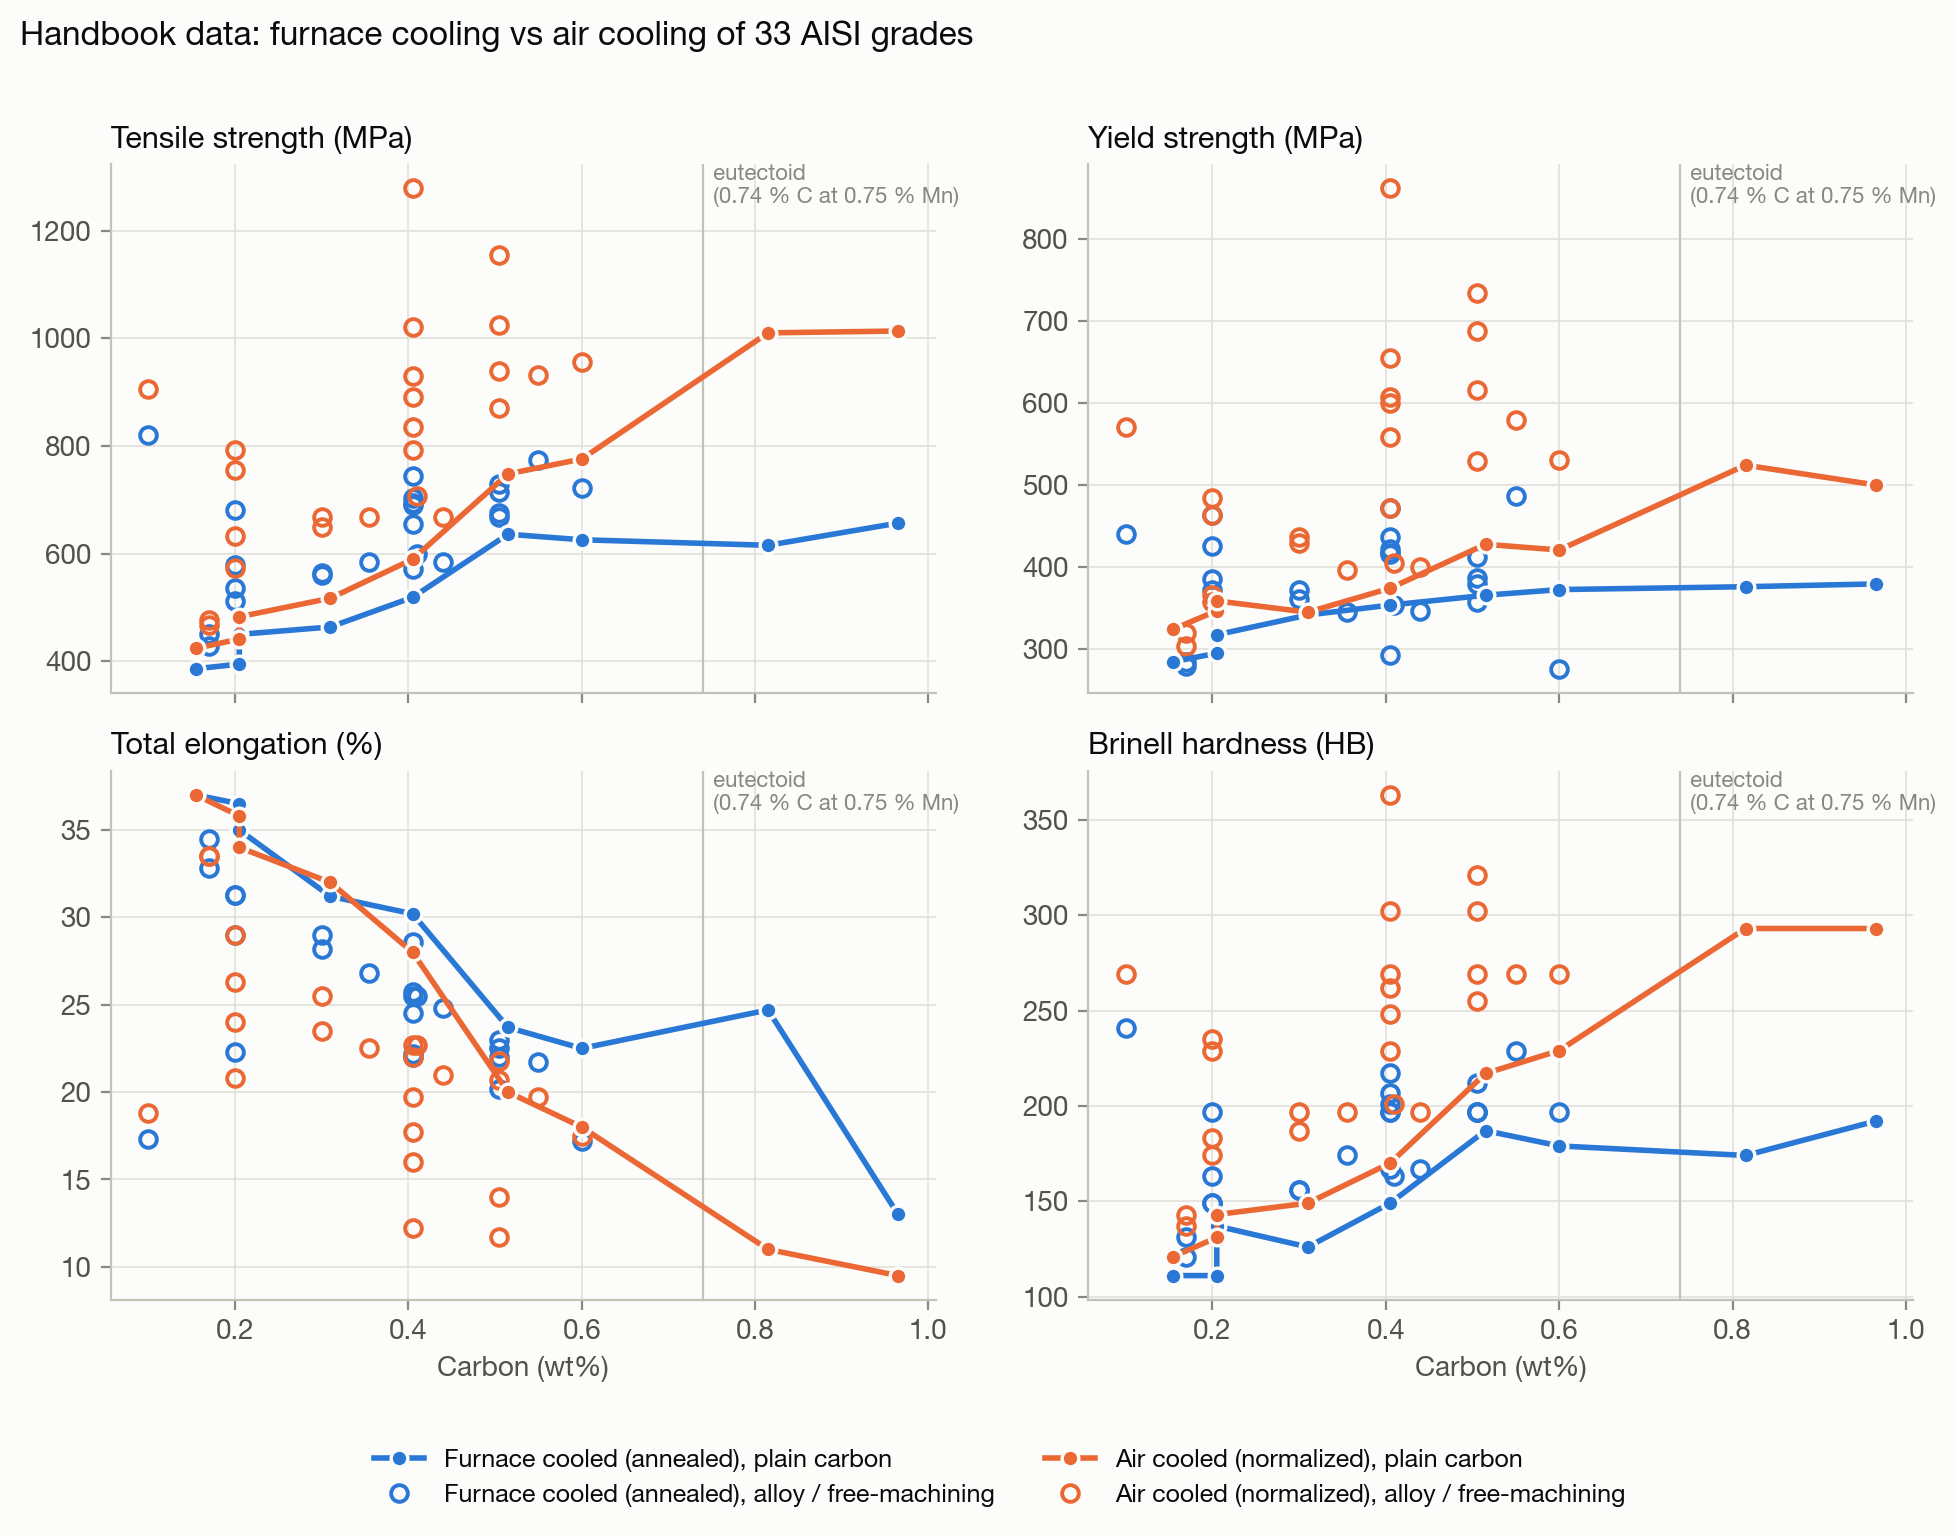

In [3]:
fig("fig01_handbook_properties_vs_carbon")

In [4]:
pairs = pd.read_csv(R / "s01_route_pairs.csv")
pairs[[c for c in pairs.columns if c.endswith("_delta")]].describe().round(1)

,UTS_MPa_delta,YS_MPa_delta,El_pct_delta,HB_delta
count,33,33,33,33
mean,170,113,-3.6,51.7
std,131,105,3.6,36
min,27.6,-28.4,-13.7,6
25%,74.1,39.7,-5.5,25
50%,112,62.1,-3.5,40
75%,234,178,-1,72
max,534,390,1.7,146


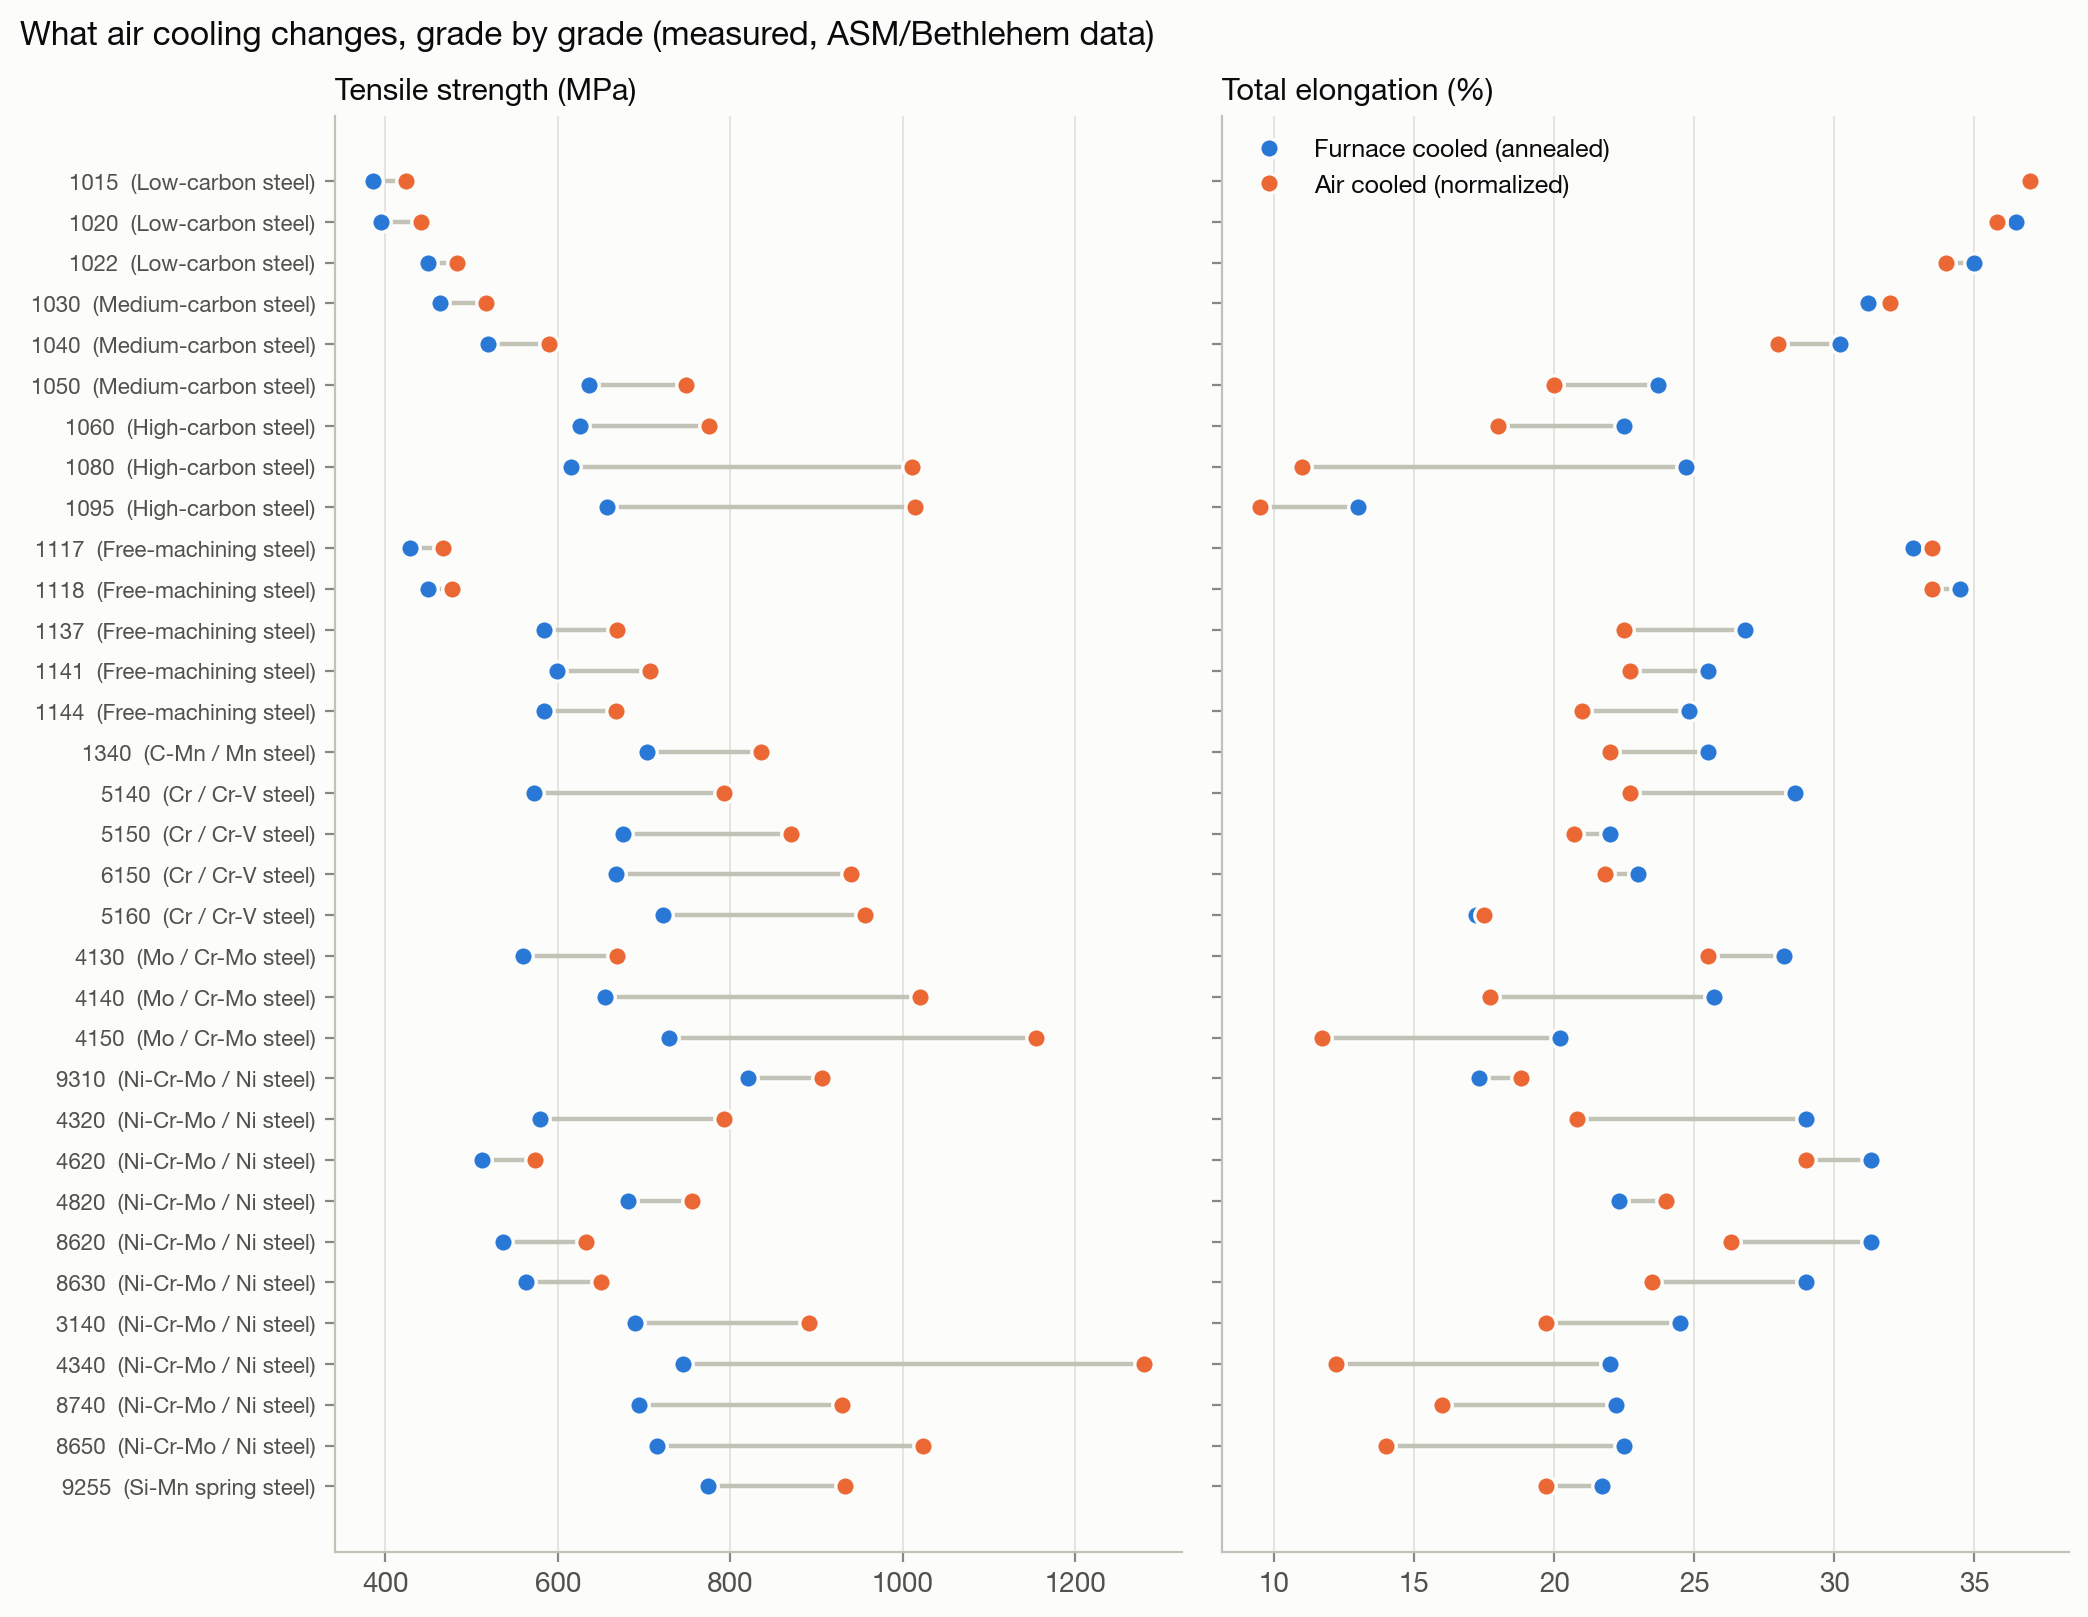

In [5]:
fig("fig02_route_effect_by_grade", 950)

## Practice: at which temperatures were these steels treated?
The steel corner of the Fe-C diagram with the temperatures at which the 33 handbook grades were actually
annealed and normalised, and the defaults the tool uses (fitted to that practice). Normalising is done about
60 °C hotter than annealing, so the two routes differ in temperature as well as in cooling rate.

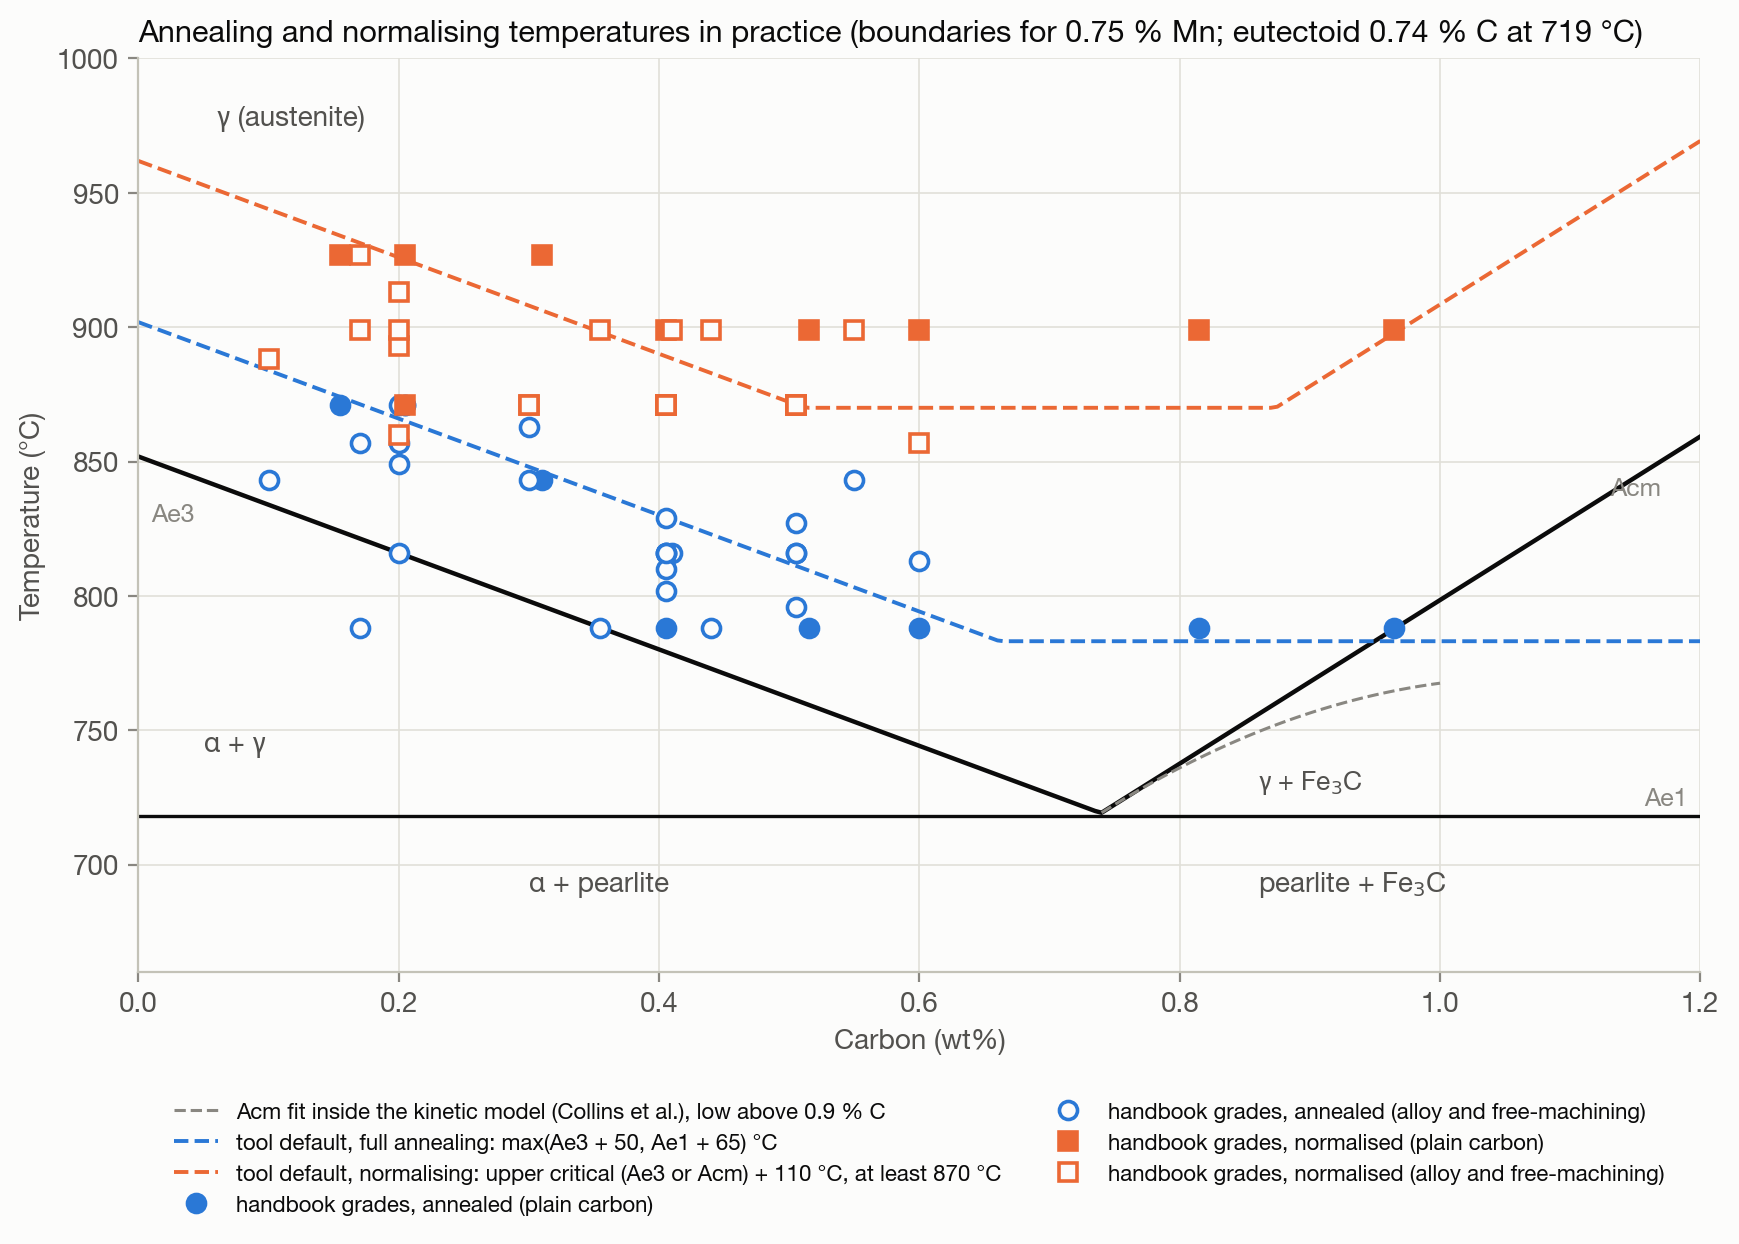

In [6]:
fig("fig26_heat_treatment_practice", 850)

**Reading the data.** Air cooling never lowered the tensile strength of a handbook grade (all 33 deltas
are positive); elongation fell for most grades. The largest effects are in eutectoid/high-carbon steels
(finer pearlite) and in Cr-Mo / Ni-Cr-Mo steels (bainite formation).